# Spam Message Classifier
### CodeNova AI/ML Internship — Task 2 | Natural Language Processing (NLP)

In [1]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
import zipfile
import urllib.request
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import zipfile
import pandas as pd

with zipfile.ZipFile("sms+spam+collection.zip", "r") as z:
    with z.open("SMSSpamCollection") as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"]
        )

print("Dataset Loaded Successfully!")
print(df.shape)

df.head()

Dataset Loaded Successfully!
(5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**Dataset note:** The UCI dataset description reports 5,574 messages, while the `SMSSpamCollection` text file in this archive contains 5,572 rows when read. This notebook reports the actual rows in the file; duplicate removal reduces the count further.

In [5]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLabel counts:")
print(df["label"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 43.6 KB

Missing values:
label      0
message    0
dtype: int64

Duplicate rows: 403

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64


In [6]:
before = len(df)

df = df.dropna(subset=["label", "message"]).copy()
df = df.drop_duplicates().reset_index(drop=True)

print("Rows before cleaning:", before)
print("Rows after cleaning:", len(df))
print("Rows removed:", before - len(df))
print("\nCleaned label counts:")
print(df["label"].value_counts())

Rows before cleaning: 5572
Rows after cleaning: 5169
Rows removed: 403

Cleaned label counts:
label
ham     4516
spam     653
Name: count, dtype: int64


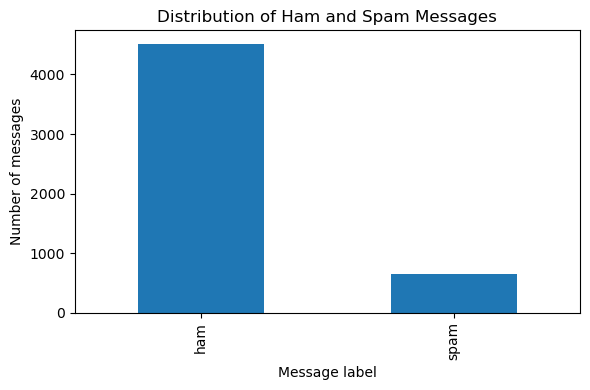

In [7]:
plt.figure(figsize=(6, 4))
df["label"].value_counts().reindex(["ham", "spam"]).plot(kind="bar")
plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message label")
plt.ylabel("Number of messages")
plt.tight_layout()
plt.show()

In [8]:
X = df["message"].astype(str)
y = df["label"]

print("Number of messages:", len(X))
print("Number of labels:", len(y))
print("\nAvailable labels:", sorted(y.unique()))

Number of messages: 5169
Number of labels: 5169

Available labels: ['ham', 'spam']


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4135
Testing messages: 1034


In [10]:
nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english"
    )),
    ("classifier", MultinomialNB())
])

lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english"
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Both model pipelines are ready.")

Both model pipelines are ready.


In [11]:
nb_model.fit(X_train, y_train)
lr_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [12]:
models = {
    "Multinomial Naive Bayes": nb_model,
    "Logistic Regression": lr_model
}

results = []
test_predictions = {}

for model_name, model in models.items():
    predictions = model.predict(X_test)
    test_predictions[model_name] = predictions

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (spam)": precision_score(
            y_test, predictions, pos_label="spam", zero_division=0
        ),
        "Recall (spam)": recall_score(
            y_test, predictions, pos_label="spam", zero_division=0
        ),
        "F1-score (spam)": f1_score(
            y_test, predictions, pos_label="spam", zero_division=0
        )
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

,Accuracy,Precision (spam),Recall (spam),F1-score (spam)
Model,,,,
Multinomial Naive Bayes,0.9671,1.0000,0.7405,0.8509
Logistic Regression,0.9565,0.9778,0.6718,0.7964


In [13]:
best_model_name = results_df["Precision (spam)"].idxmax()
best_model = models[best_model_name]
best_predictions = test_predictions[best_model_name]

print("Selected model:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=["ham", "spam"],
    zero_division=0
))

Selected model: Multinomial Naive Bayes

Classification report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       1.00      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.96      1034



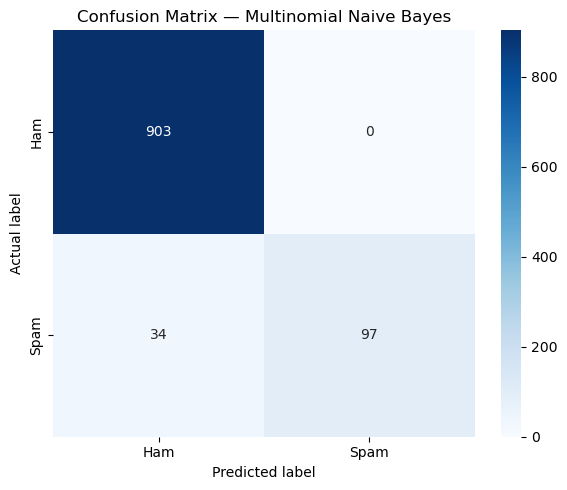

In [14]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["ham", "spam"]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

In [15]:
def predict_message(message):
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Please enter a non-empty message.")

    prediction = best_model.predict([message])[0]
    print("Message:", message)
    print("Prediction:", "SPAM" if prediction == "spam" else "HAM (NORMAL)")
    return prediction

# Example tests
predict_message("Congratulations! You have won a free prize. Click now!")
print()
predict_message("Hi, are we still meeting for class tomorrow?")

Message: Congratulations! You have won a free prize. Click now!
Prediction: SPAM

Message: Hi, are we still meeting for class tomorrow?
Prediction: HAM (NORMAL)


np.str_('ham')

In [16]:
# Optional: enter a message of your own
my_message = input("Enter an SMS message: ")
predict_message(my_message)

Enter an SMS message:  Congratulations! You have won a free prize. Click now!


Message: Congratulations! You have won a free prize. Click now!
Prediction: SPAM


np.str_('spam')

In [17]:
MODEL_PATH = Path("spam_classifier.joblib")
joblib.dump(best_model, MODEL_PATH)

print(f"Model saved successfully: {MODEL_PATH.resolve()}")

Model saved successfully: /drive/notebooks/task2/spam_classifier.joblib


In [18]:
loaded_model = joblib.load("spam_classifier.joblib")

sample_message = "Your appointment is confirmed for 10 AM."
loaded_prediction = loaded_model.predict([sample_message])[0]

print("Message:", sample_message)
print("Prediction:", "SPAM" if loaded_prediction == "spam" else "HAM (NORMAL)")

Message: Your appointment is confirmed for 10 AM.
Prediction: HAM (NORMAL)


## 16. Project conclusion

In this project, we:
1. Loaded and explored a public SMS spam dataset.
2. Removed missing and duplicate rows.
3. Split the data into training and held-out test sets.
4. Used TF-IDF to convert text into numerical features.
5. Trained Multinomial Naive Bayes and Logistic Regression.
6. Compared accuracy, precision, recall, and F1-score.
7. Visualized the selected model's confusion matrix.
8. Tested custom messages and saved the complete model pipeline.
**Dataset credit:** UCI Machine Learning Repository, SMS Spam Collection.